In [5]:
# Import du fichier et des bibliothèques utilisées
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


chemin_donnees = Path("billets.csv")
if not chemin_donnees.exists():
    raise FileNotFoundError(
        "Le fichier billets.csv est introuvable. Placez-le dans le dossier du projet, "
        "à côté du notebook."
    )
df_billets = pd.read_csv(chemin_donnees, sep=";")


In [6]:
# Exploration rapide du dataset
df_billets.info

<bound method DataFrame.info of       is_genuine  diagonal  height_left  height_right  margin_low  margin_up  \
0           True    171.81       104.86        104.95        4.52       2.89   
1           True    171.46       103.36        103.66        3.77       2.99   
2           True    172.69       104.48        103.50        4.40       2.94   
3           True    171.36       103.91        103.94        3.62       3.01   
4           True    171.73       104.28        103.46        4.04       3.48   
...          ...       ...          ...           ...         ...        ...   
1495       False    171.75       104.38        104.17        4.42       3.09   
1496       False    172.19       104.63        104.44        5.27       3.37   
1497       False    171.80       104.01        104.12        5.51       3.36   
1498       False    172.06       104.28        104.06        5.17       3.46   
1499       False    171.47       104.15        103.82        4.63       3.37   

      l

In [7]:
# Nombre de vrais et faux billets
df_billets["is_genuine"].value_counts()

is_genuine
True     1000
False     500
Name: count, dtype: int64

In [8]:
# Proportion de vrais et faux billets
(df_billets["is_genuine"].value_counts(normalize=True).mul(100).round(1))


is_genuine
True     66.7
False    33.3
Name: proportion, dtype: float64

In [9]:
# Vérification des valeurs nulles
df_billets.isna().sum()

is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

In [10]:
# Vérification des doublons
df_billets.duplicated().sum()

np.int64(0)

In [11]:
# Exploration Statistique du dataset
df_billets.describe().round(2)

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1500.00,1500.00,1500.00,1463.00,1500.00,1500.00
mean,171.96,104.03,103.92,4.49,3.15,112.68
std,0.31,0.30,0.33,0.66,0.23,0.87
min,171.04,103.14,102.82,2.98,2.27,109.49
25%,171.75,103.82,103.71,4.01,2.99,112.03
50%,171.96,104.04,103.92,4.31,3.14,112.96
75%,172.17,104.23,104.15,4.87,3.31,113.34
max,173.01,104.88,104.95,6.90,3.91,114.44


In [12]:
# Comparaison entre vrai et faux billet moyen
df_billets.groupby("is_genuine").mean(numeric_only=True).round(2)

,diagonal,height_left,height_right,margin_low,margin_up,length
is_genuine,,,,,,
False,171.90,104.19,104.14,5.22,3.35,111.63
True,171.99,103.95,103.81,4.12,3.05,113.20


Les faux billets semblent notamment avoir :

une longueur plus faible : 111,63 contre 113,20 mm ;
une marge basse plus importante : 5,22 contre 4,12 mm ;
une marge haute plus importante : 3,35 contre 3,05 mm ;
des hauteurs légèrement supérieures.

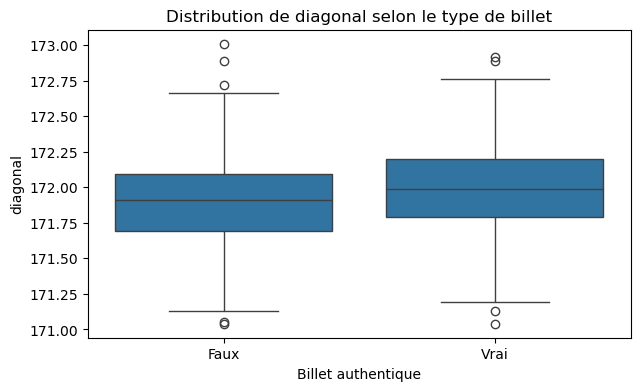

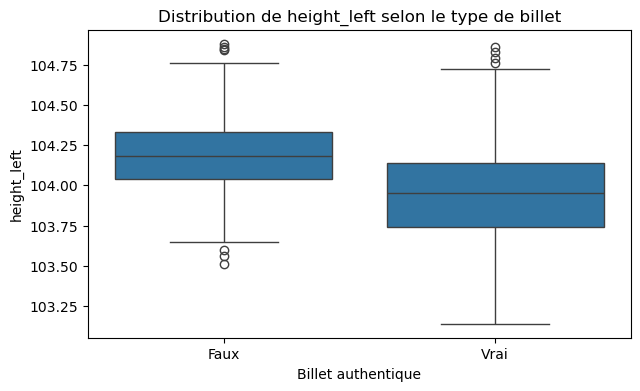

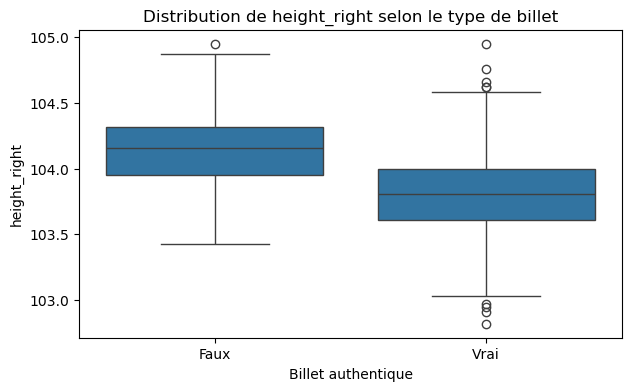

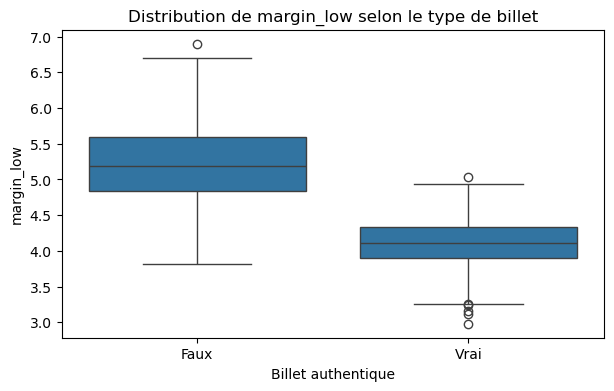

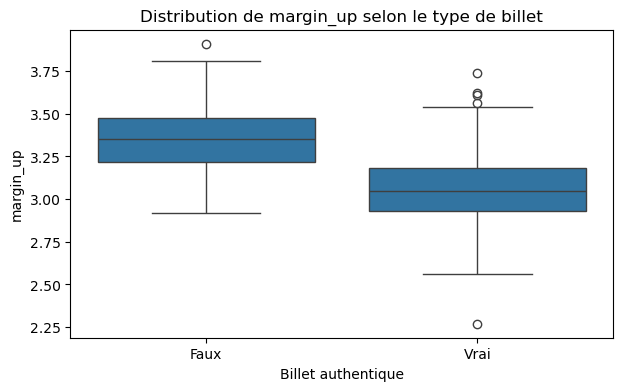

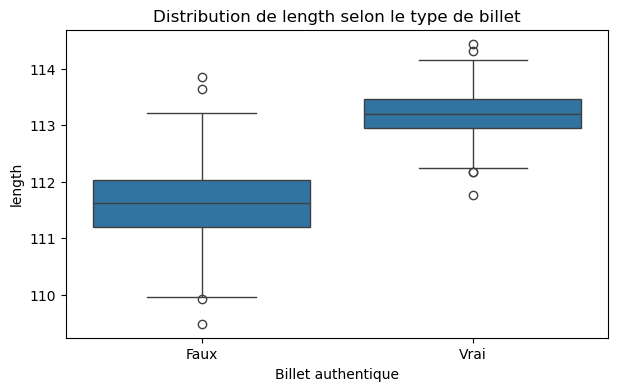

In [13]:
# Analyse des distributions entre vrai et faux billet pour chaque variable
features = [
    "diagonal",
    "height_left",
    "height_right",
    "margin_low",
    "margin_up",
    "length"
]

for feature in features:
    plt.figure(figsize=(7, 4))
    
    sns.boxplot(
        data=df_billets,
        x="is_genuine",
        y=feature
    )
    
    plt.title(f"Distribution de {feature} selon le type de billet")
    plt.xlabel("Billet authentique")
    plt.ylabel(feature)
    plt.xticks([0, 1], ["Faux", "Vrai"])
    
    plt.show()

Analyse des distributions

L'analyse descriptive met en évidence plusieurs différences géométriques entre les billets authentiques et les contrefaçons. 
Les variables margin_low, margin_up et length présentent notamment des écarts importants entre les deux populations. 
Les variables height_left et height_right montrent également des différences, tandis que diagonal semble moins discriminante prise isolément.

Ces premières observations suggèrent que plusieurs caractéristiques géométriques pourraient permettre de distinguer les billets authentiques des contrefaçons. 
La performance des différents algorithmes permettra de confirmer leur pouvoir prédictif.

In [14]:
# Répartition des valeurs manquantes de margin_low
df_billets[df_billets["margin_low"].isna()]["is_genuine"].value_counts()

is_genuine
True     29
False     8
Name: count, dtype: int64

In [15]:
# Pourcentage de valeurs manquantes dans vrai et faux billets
pd.crosstab(
    df_billets["is_genuine"],
    df_billets["margin_low"].isna(),
    normalize="index"
).mul(100).round(2)


margin_low,False,True
is_genuine,,
False,98.4,1.6
True,97.1,2.9


Analyse des valeurs manquantes : les valeurs manquantes de margin_low représentent 1,6 % des contrefaçons et 2,9 % des billets authentiques. 
La différence entre les deux groupes reste faible. Les valeurs manquantes ne semblent donc pas fortement dépendre de la nature du billet. 
Nous conservons les observations et remplaçons les valeurs manquantes par la médiane calculée sur le jeu d'entraînement.

In [16]:
df_billets["margin_low"].describe().round(2)

count    1463.00
mean        4.49
std         0.66
min         2.98
25%         4.01
50%         4.31
75%         4.87
max         6.90
Name: margin_low, dtype: float64

<Figure size 800x500 with 0 Axes>

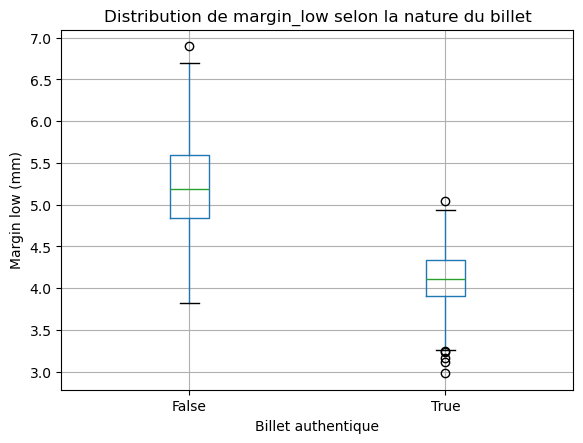

In [17]:
# Distribution de margin_low pour les vrais et faux billets
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

df_billets.boxplot(
    column="margin_low",
    by="is_genuine"
)

plt.title("Distribution de margin_low selon la nature du billet")
plt.suptitle("")
plt.xlabel("Billet authentique")
plt.ylabel("Margin low (mm)")
plt.show()

margin_low est une variable particulièrement discriminante. Les billets contrefaits (False) présentent généralement une valeur de margin_low plus élevée que les billets authentiques (True). 
La médiane est d'environ 5,2 mm pour les contrefaçons contre 4,1 mm pour les billets authentiques.

Les distributions sont relativement distinctes, même si quelques valeurs atypiques sont présentes dans les deux groupes. 
Cette séparation suggère que margin_low pourrait jouer un rôle important dans la détection des contrefaçons.

In [18]:
# Séparer les variables et la cible

variables = [
    "diagonal",
    "height_left",
    "height_right",
    "margin_low",
    "margin_up",
    "length"
]                       # Variables à utiliser pour l'entrainement

X = df_billets[variables].copy()

# 1 = contrefaçon
# 0 = billet authentique
y = (~df_billets["is_genuine"]).astype(int)  # inversion de la logique (is genuine = true = 0, is genuine = false = 1 comme on cherche les faux billets avec les modèles)

In [19]:
print("Dimensions de X :", X.shape)
print("Répartition de y :")
print(y.value_counts())

Dimensions de X : (1500, 6)
Répartition de y :
is_genuine
0    1000
1     500
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,  # pour retrouver le même partage
    stratify=y       # garde la proportion de billets vrais et faux
)

print("Train :", X_train.shape)
print("Test :", X_test.shape)


Train : (1200, 6)
Test : (300, 6)


In [21]:
# Vérifier si perte de données
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)  # Calcul de la médiane sur le dataset d'entrainement pour remplacer les valeurs manquantes
X_test_imputed = imputer.transform(X_test)       # Recuperer la médiane calculée précedemment et l'ajouter au dataset test

print("Valeurs manquantes après imputation :")
print(X_train_imputed.shape)

Valeurs manquantes après imputation :
(1200, 6)


In [22]:
# Import des modèles 

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans


def modele_logistique():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(random_state=42, class_weight="balanced"))
    ])


def modele_knn():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ])


def modele_random_forest():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ])


def modele_kmeans():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KMeans(
            n_clusters=2,
            random_state=42,
            n_init=10
        ))
    ])

In [23]:
# fonction d'évaluation
from sklearn.metrics import (
    accuracy_score,   # Sur 100 prédictions, combien sont correctes ?
    precision_score,  # Parmi les billets que le modèle dit faux, combien sont vraiment faux ?
    recall_score,     # Parmi tous les faux billets, combien le modèle détecte
    f1_score,         # Moyenne entre precision et recall
    confusion_matrix  # visualisation des erreurs
)

def evaluer_modele(modele):
    
    modele.fit(X_train, y_train)      # Entraînement du modèle
    y_pred = modele.predict(X_test)   # Prédictions sur le test
    
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
    print("Precision :", round(precision_score(y_test, y_pred), 3))
    print("Recall :", round(recall_score(y_test, y_pred), 3))
    print("F1-score :", round(f1_score(y_test, y_pred), 3))
    
    print("\nMatrice de confusion :")
    print(confusion_matrix(y_test, y_pred))

In [24]:
# test avec Régression logistique
evaluer_modele(modele_logistique())

Accuracy : 0.99
Precision : 1.0
Recall : 0.97
F1-score : 0.985

Matrice de confusion :
[[200   0]
 [  3  97]]


In [25]:
# test avec knn
evaluer_modele(modele_knn())

Accuracy : 0.99
Precision : 1.0
Recall : 0.97
F1-score : 0.985

Matrice de confusion :
[[200   0]
 [  3  97]]


In [26]:
# test avec random forest
evaluer_modele(modele_random_forest())

Accuracy : 0.99
Precision : 1.0
Recall : 0.97
F1-score : 0.985

Matrice de confusion :
[[200   0]
 [  3  97]]


In [27]:
# tableau comparatif
resultats = []

modeles = {
    "Régression logistique": modele_logistique(),
    "KNN": modele_knn(),
    "Random Forest": modele_random_forest()
}

for nom, modele in modeles.items():
    modele.fit(X_train, y_train)
    y_pred = modele.predict(X_test)
    
    resultats.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Faux négatifs": confusion_matrix(y_test, y_pred)[1, 0]
    })

resultats_df = pd.DataFrame(resultats)

resultats_df.round(3)

,Modèle,Accuracy,Precision,Recall,F1-score,Faux négatifs
0,Régression logistique,0.99,1.0,0.97,0.985,3
1,KNN,0.99,1.0,0.97,0.985,3
2,Random Forest,0.99,1.0,0.97,0.985,3


Les trois modèles supervisés donnent ici les mêmes résultats sur le jeu de test : 99 % d'accuracy, 100 % de précision et 97 % de rappel. Sur les 100 faux billets du test, 97 sont détectés et 3 sont classés comme authentiques. C'est un bon résultat sur cet échantillon, mais il reste des faux négatifs : le modèle ne peut donc pas être présenté comme infaillible.


In [28]:
# Entrainement de kmeans

import os
os.environ["OMP_NUM_THREADS"] = "5"

modele = modele_kmeans()

modele.fit(X_train)

n_clusters=2

sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=5.
  warnings.warn(


In [29]:
# obtention des clusters
clusters_train = modele.predict(X_train)

clusters_train[:20]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1],
      dtype=int32)

In [30]:
# Comparer les clusters aux vraies classes
pd.crosstab(
    clusters_train,
    y_train,
    rownames=["Cluster"],
    colnames=["Nature réelle"]
)

Nature réelle,0,1
Cluster,,
0,9,389
1,791,11


In [31]:
# création de la correspondance
correspondance = {
    0: 1,  # Cluster 0 → contrefaçon
    1: 0   # Cluster 1 → authentique
}
y_pred_kmeans_train = [correspondance[cluster] for cluster in clusters_train]   # Transformation des clusters en prédictions

K‑Means est un algorithme non supervisé : il ne connaît pas les classes “authentique” ou “contrefaçon”. 
Il crée juste deux groupes en fonction des ressemblances entre les billets. 
Ensuite, j’ai regardé ce que contenait chaque groupe dans les données d’entraînement : le cluster 0 contient surtout des contrefaçons, et le cluster 1 surtout des billets authentiques. J’ai donc associé chaque cluster à la classe correspondante avant de faire les prédictions.

In [32]:
# Prédiction des clusters du jeu de test
clusters_test = modele.predict(X_test)

clusters_test[:20]

array([0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1],
      dtype=int32)

In [33]:
# transformation des clusters en classes
y_pred_kmeans = [correspondance[cluster] for cluster in clusters_test]

In [34]:
# Evaluation de k-means
print("Accuracy :", round(accuracy_score(y_test, y_pred_kmeans), 3))
print("Precision :", round(precision_score(y_test, y_pred_kmeans), 3))
print("Recall :", round(recall_score(y_test, y_pred_kmeans), 3))
print("F1-score :", round(f1_score(y_test, y_pred_kmeans), 3))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_kmeans))

Accuracy : 0.987
Precision : 0.99
Recall : 0.97
F1-score : 0.98

Matrice de confusion :
[[199   1]
 [  3  97]]


K-Means est un peu derrière les modèles supervisés sur ce jeu de test : il classe un billet authentique comme contrefait, et manque aussi trois faux billets. Les scores restent proches. Pour le projet, je garde surtout les modèles supervisés pour la comparaison, car ils apprennent directement à partir des étiquettes vrai/faux.


In [35]:
# importance des variables
modele_rf = modele_random_forest()

modele_rf.fit(X_train, y_train)

importances = modele_rf.named_steps["model"].feature_importances_.round(2)

importance_variables = pd.DataFrame({
    "Variable": variables,
    "Importance": importances
}).sort_values("Importance", ascending=False)

importance_variables

,Variable,Importance
5,length,0.48
3,margin_low,0.33
4,margin_up,0.10
1,height_left,0.04
2,height_right,0.04
0,diagonal,0.01


L'analyse du Random Forest donne surtout du poids à length (48 %) et margin_low (33 %). Cela rejoint en partie les écarts vus dans les graphiques. Cette importance décrit les décisions de ce modèle sur ces données ; elle ne veut pas dire que ces mesures expliquent à elles seules pourquoi un billet est faux.


In [36]:
# Validation croisée sur le jeu d'entraînement
from sklearn.model_selection import StratifiedKFold, cross_validate

modeles = {
    "Régression logistique": modele_logistique(),
    "KNN": modele_knn(),
    "Random Forest": modele_random_forest()
}

# Chaque pli garde à peu près la même proportion de billets vrais et faux.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats_cv = []

for nom, modele in modeles.items():
    scores = cross_validate(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )
    ligne = {"Modèle": nom}
    for metrique in ["accuracy", "precision", "recall", "f1"]:
        valeurs = scores[f"test_{metrique}"]
        ligne[f"{metrique} moyenne"] = valeurs.mean()
        ligne[f"{metrique} écart-type"] = valeurs.std(ddof=1)
    resultats_cv.append(ligne)

resultats_cv_df = pd.DataFrame(resultats_cv)
resultats_cv_df.round(3)


,Modèle,accuracy moyenne,accuracy écart-type,precision moyenne,precision écart-type,recall moyenne,recall écart-type,f1 moyenne,f1 écart-type
0,Régression logistique,0.990,0.002,0.983,0.011,0.988,0.013,0.985,0.003
1,KNN,0.991,0.006,0.992,0.007,0.980,0.014,0.986,0.009
2,Random Forest,0.991,0.007,0.992,0.007,0.980,0.019,0.986,0.011


Les moyennes résument les scores obtenus sur les cinq plis. L'écart-type donne une idée de leur variation d'un pli à l'autre : plus il est petit, plus les résultats sont réguliers dans cette validation. Ici, les modèles restent très proches, donc le petit avantage du Random Forest ne suffit pas à dire qu'il sera toujours meilleur.

Le jeu de test est gardé à part pour l'évaluation finale. Il faut éviter de choisir le modèle en fonction de ses résultats sur ce jeu, car cela rendrait l'évaluation moins indépendante.


In [37]:
# Modele final : regression logistique, meilleur rappel moyen en validation croisee.
modele_final = modele_logistique()

modele_final.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', random_state=42))])

In [38]:
# fonction de prédiction pour transformer notre modèle en petite application utilisable
def predire_billet(diagonal, height_left, height_right,
                   margin_low, margin_up, length):
    
    billet = pd.DataFrame([{
        "diagonal": diagonal,
        "height_left": height_left,
        "height_right": height_right,
        "margin_low": margin_low,
        "margin_up": margin_up,
        "length": length
    }])
    
    prediction = modele_final.predict(billet)[0]
    
    if prediction == 1:
        return "Billet contrefait"
    else:
        return "Billet authentique"

In [39]:
# Exemple de prédiction avec une ligne du jeu de test
exemple = X_test.iloc[0]
predire_billet(
    exemple["diagonal"], exemple["height_left"], exemple["height_right"],
    exemple["margin_low"], exemple["margin_up"], exemple["length"]
)


'Billet contrefait'

In [40]:
# verification du test
vraie_valeur = y_test.iloc[0]

print("Valeur réelle :", vraie_valeur)
print("Prédiction :", modele_final.predict(pd.DataFrame([X_test.iloc[0]]))[0])

Valeur réelle : 1
Prédiction : 1


In [41]:
# Evaluation finale du modèle sur le jeu de test
from sklearn.metrics import confusion_matrix, classification_report

y_pred_final = modele_final.predict(X_test)
print("Matrice de confusion (lignes = vraie classe, colonnes = prédiction) :")
print(confusion_matrix(y_test, y_pred_final))
print("\nRapport de classification :")
print(classification_report(
    y_test, y_pred_final,
    target_names=["Authentique", "Contrefait"],
    digits=3,
    zero_division=0
))


Matrice de confusion (lignes = vraie classe, colonnes = prédiction) :
[[200   0]
 [  3  97]]

Rapport de classification :
              precision    recall  f1-score   support

 Authentique      0.985     1.000     0.993       200
  Contrefait      1.000     0.970     0.985       100

    accuracy                          0.990       300
   macro avg      0.993     0.985     0.989       300
weighted avg      0.990     0.990     0.990       300



In [42]:
# Enregistrement du modèle final
import joblib
from pathlib import Path

chemin_modele = Path("modele_billets.pkl")
joblib.dump(modele_final, chemin_modele)
print(f"Modèle enregistré : {chemin_modele.name}")


Modèle enregistré : modele_billets.pkl
